In [1]:
# (a) Import Libraries

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import Dense, Dropout

from tensorflow.keras.optimizers import Adam

In [5]:
DATA_PATH = r"C:/Users/Dell/Downloads/caltech-101/caltech-101/101_ObjectCategories/101_ObjectCategories"
print("Dataset path:", DATA_PATH)

Dataset path: C:/Users/Dell/Downloads/caltech-101/caltech-101/101_ObjectCategories/101_ObjectCategories


In [6]:
# (a) Select any 5 object categories

categories = [
    "starfish",
    "butterfly",
    "chair",
    "water_lilly",
    "wheelchair"
]
print("Selected Categories:")
print(categories)

Selected Categories:
['starfish', 'butterfly', 'chair', 'water_lilly', 'wheelchair']


In [7]:
# (b) Resize images to 224 x 224
#     Apply VGG16 preprocessing

datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    DATA_PATH,
    target_size=(224, 224),
    classes=categories,
    class_mode="categorical",
    batch_size=16,
    subset="training"
)

test_data = datagen.flow_from_directory(
    DATA_PATH,
    target_size=(224, 224),
    classes=categories,
    class_mode="categorical",
    batch_size=16,
    subset="validation",
    shuffle=False
)

print("Training images:", train_data.samples)
print("Testing images:", test_data.samples)

Found 270 images belonging to 5 classes.
Found 65 images belonging to 5 classes.
Training images: 270
Testing images: 65


In [8]:
# (c) Load VGG16 with ImageNet weights
#     Remove original classification layers

base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("VGG16 loaded successfully")

VGG16 loaded successfully


In [9]:
base_model.trainable = False
print("VGG16 layers frozen")

VGG16 layers frozen


In [10]:
# (e) Custom Classifier
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(5, activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,780,997 (56.39 MB)

 Trainable params: 66,309 (259.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [12]:
# (f) Compile Model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [13]:
# (g) Train custom classification layers
history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=5
)

Epoch 1/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 120s 7s/step - accuracy: 0.2630 - loss: 7.3345 - val_accuracy: 0.3077 - val_loss: 3.4679
Epoch 2/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 107s 6s/step - accuracy: 0.3407 - loss: 6.1925 - val_accuracy: 0.4308 - val_loss: 2.3606
Epoch 3/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 108s 6s/step - accuracy: 0.3407 - loss: 5.3055 - val_accuracy: 0.5692 - val_loss: 1.6274
Epoch 4/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 109s 6s/step - accuracy: 0.4519 - loss: 3.7328 - val_accuracy: 0.6769 - val_loss: 1.1871
Epoch 5/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 110s 7s/step - accuracy: 0.5407 - loss: 2.7762 - val_accuracy: 0.7077 - val_loss: 0.9569


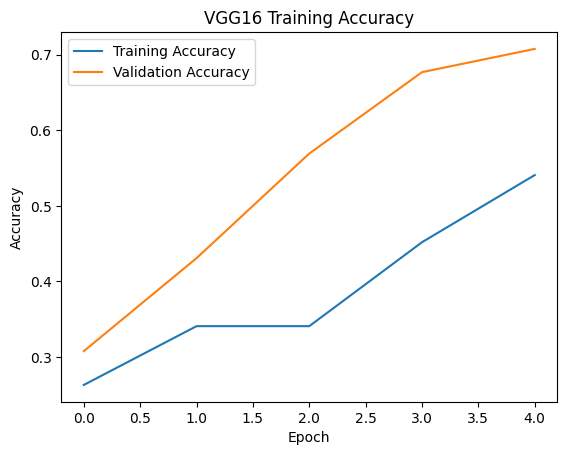

In [14]:
# Training and validation accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("VGG16 Training Accuracy")

plt.legend()
plt.show()

In [15]:
# (g) Evaluate the model

loss, accuracy = model.evaluate(test_data)

print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

5/5 ━━━━━━━━━━━━━━━━━━━━ 22s 4s/step - accuracy: 0.7077 - loss: 0.9569
Test Accuracy: 0.7076923251152039
Test Accuracy (%): 70.76923251152039


In [16]:
# (h) Predict object categories for 5 images
predictions = model.predict(test_data)
class_names = list(test_data.class_indices.keys())

print("Class Names:")
print(class_names)

5/5 ━━━━━━━━━━━━━━━━━━━━ 25s 5s/step
Class Names:
['starfish', 'butterfly', 'chair', 'water_lilly', 'wheelchair']


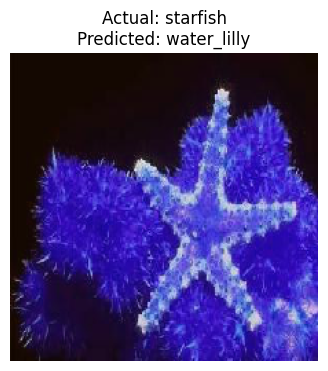

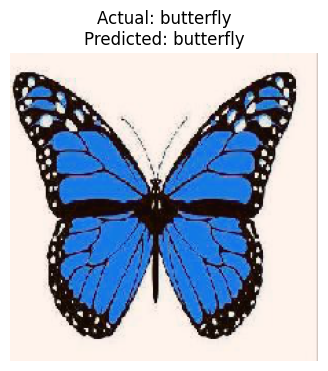

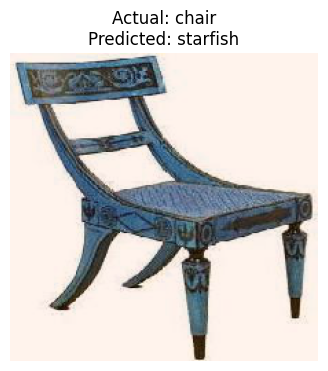

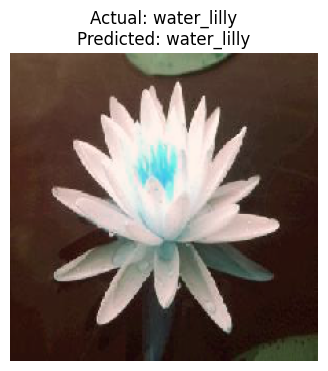

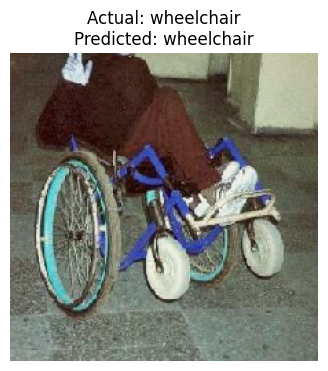

Displayed 5 different object categories.


In [18]:
# (h) Display 5 different object predictions

import numpy as np
import matplotlib.pyplot as plt

class_names = list(test_data.class_indices.keys())

# Keep track of classes already displayed
shown_classes = set()

# Go through test batches
test_data.reset()

while len(shown_classes) < 5:

    images, labels = next(test_data)

    predictions = model.predict(images, verbose=0)

    for i in range(len(images)):

        actual_class = np.argmax(labels[i])
        predicted_class = np.argmax(predictions[i])

        # Show only one image from each actual category
        if actual_class not in shown_classes:

            shown_classes.add(actual_class)

            # Convert image for display
            image = images[i]
            image = image - image.min()
            image = image / image.max()

            plt.figure(figsize=(4, 4))
            plt.imshow(image)
            plt.axis("off")

            plt.title(
                "Actual: " + class_names[actual_class] +
                "\nPredicted: " + class_names[predicted_class]
            )

            plt.show()

        # Stop after 5 different classes
        if len(shown_classes) == 5:
            break

print("Displayed 5 different object categories.")